# PPC Wasted-Spend Audit: CPA, ROAS and Budget Reallocation Rules

**Business question:** how much of an ad budget is spent on ads that never convert, and what would simple, rule-based optimisation recover?

This is the audit I'd run on a new Amazon Sponsored Products, Google or Meta account before touching bids. The steps are the same on any platform:

1. **Account health KPIs**: CTR, CPC, conversion rate, CPA, ROAS
2. **Funnel by campaign**: where impressions turn into (approved) sales
3. **Wasted spend**: spend on ads with zero approved conversions
4. **Audience efficiency**: CPA by age, gender and interest (like a search-term or targeting report)
5. **Optimisation rules**: pause / reduce / scale rules with thresholds, plus a what-if simulation

Dataset: [Sales Conversion Optimization](https://www.kaggle.com/datasets/loveall/clicks-conversion-tracking), 1,143 ads from an anonymised company's social media campaigns. The data has no revenue column, so revenue per approved conversion is an **explicit, adjustable assumption** (see `VALUE_PER_CONVERSION`).

> **TL;DR**
> 1. 25% of ad spend ($14,754) went to ads with zero approved sales.
> 2. Account CPA is $54.41 against a $30 target (ROAS 1.84x at an assumed $100 per sale); the best audience cell runs at $25.55 CPA, the worst at $119.94.
> 3. Three simple pause / reduce / scale rules project +48% approved sales on the same budget (CPA $54.41 to $36.83). Treat it as a direction to test, not a guarantee.

In [1]:
import glob, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

def find_file(name):
    for root in ["/kaggle/input", "../input", "data", "/workspace/kaggle/data"]:
        hits = glob.glob(os.path.join(root, "**", name), recursive=True)
        if hits:
            return hits[0]
    raise FileNotFoundError(name)

ads = pd.read_csv(find_file("KAG_conversion_data.csv"))
ads = ads.rename(columns={"xyz_campaign_id": "campaign", "Spent": "Spend", "Total_Conversion": "Leads", "Approved_Conversion": "Sales"})
ads["campaign"] = ads["campaign"].map({916: "Campaign A (916)", 936: "Campaign B (936)", 1178: "Campaign C (1178)"})

# Business assumptions: change these to match your own account
VALUE_PER_CONVERSION = 100.0   # assumed revenue per approved conversion (USD)
TARGET_CPA = 30.0              # break-even style target cost per approved conversion (USD)

print(ads.shape)
ads.head()

(1143, 11)


,ad_id,campaign,fb_campaign_id,age,gender,interest,Impressions,Clicks,Spend,Leads,Sales
0,708746,Campaign A (916),103916,30-34,M,15,7350,1,1.43,2,1
1,708749,Campaign A (916),103917,30-34,M,16,17861,2,1.82,2,0
2,708771,Campaign A (916),103920,30-34,M,20,693,0,0.00,1,0
3,708815,Campaign A (916),103928,30-34,M,28,4259,1,1.25,1,0
4,708818,Campaign A (916),103928,30-34,M,28,4133,1,1.29,1,1


## 1. Account health KPIs

In [2]:
def kpis(g):
    imp, clk, sp, leads, sales = g["Impressions"].sum(), g["Clicks"].sum(), g["Spend"].sum(), g["Leads"].sum(), g["Sales"].sum()
    return pd.Series({
        "Spend": sp, "Impressions": imp, "Clicks": clk, "Leads": leads, "Sales": sales,
        "CTR": clk / imp if imp else np.nan,
        "CPC": sp / clk if clk else np.nan,
        "CVR (click to sale)": sales / clk if clk else np.nan,
        "Lead approval rate": sales / leads if leads else np.nan,
        "CPA": sp / sales if sales else np.nan,
        "ROAS": sales * VALUE_PER_CONVERSION / sp if sp else np.nan,
    })

fmt = {"Spend": "${:,.0f}", "Impressions": "{:,.0f}", "Clicks": "{:,.0f}", "Leads": "{:,.0f}", "Sales": "{:,.0f}",
       "CTR": "{:.3%}", "CPC": "${:.2f}", "CVR (click to sale)": "{:.2%}", "Lead approval rate": "{:.1%}", "CPA": "${:.2f}", "ROAS": "{:.2f}x"}
total = kpis(ads).to_frame("Account").T
by_campaign = ads.groupby("campaign").apply(kpis)
pd.concat([by_campaign, total]).style.format(fmt)

,Spend,Impressions,Clicks,Leads,Sales,CTR,CPC,CVR (click to sale),Lead approval rate,CPA,ROAS
Campaign A (916),$150,"482,925",113,58,24,0.023%,$1.32,21.24%,41.4%,$6.24,16.03x
Campaign B (936),"$2,893","8,128,187","1,984",537,183,0.024%,$1.46,9.22%,34.1%,$15.81,6.32x
Campaign C (1178),"$55,662","204,823,716","36,068","2,669",872,0.018%,$1.54,2.42%,32.7%,$63.83,1.57x
Account,"$58,705","213,434,828","38,165","3,264","1,079",0.018%,$1.54,2.83%,33.1%,$54.41,1.84x


**Reading the table:** Campaign C takes almost all of the budget, so its efficiency decides account profitability. The smaller campaigns are cheap tests. Their CPA is better, but at their low volume it may not scale.

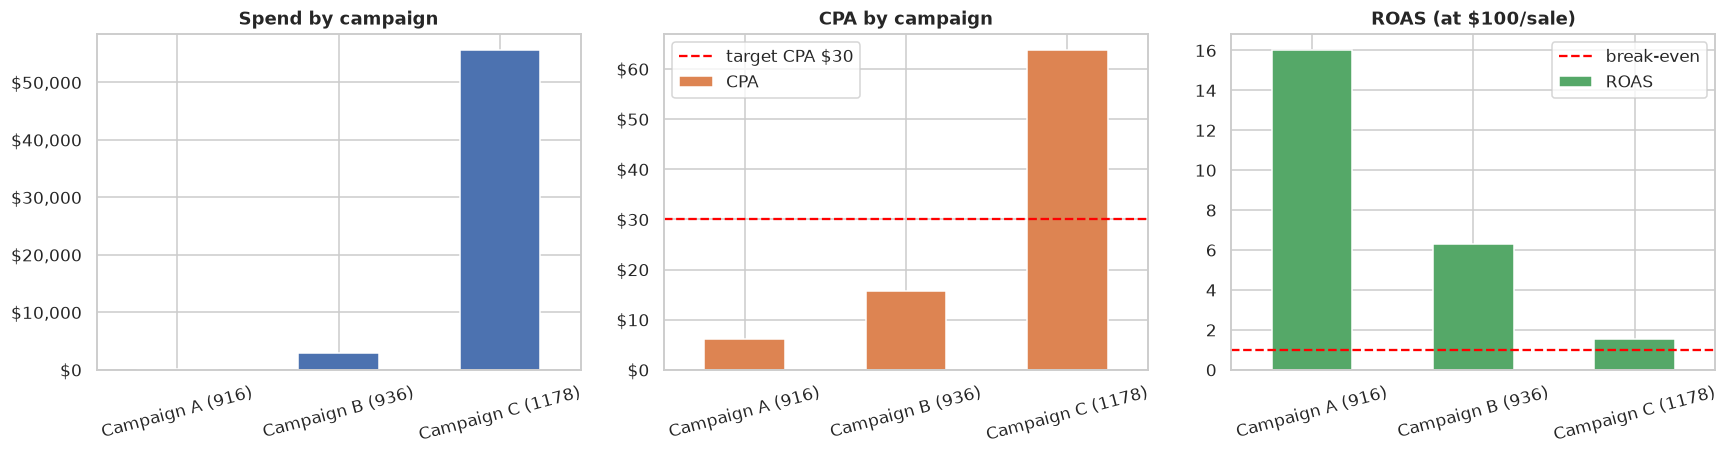

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
by_campaign["Spend"].plot.bar(ax=axes[0], color="#4c72b0"); axes[0].set_title("Spend by campaign")
by_campaign["CPA"].plot.bar(ax=axes[1], color="#dd8452"); axes[1].axhline(TARGET_CPA, ls="--", c="red", label=f"target CPA ${TARGET_CPA:.0f}"); axes[1].legend(); axes[1].set_title("CPA by campaign")
by_campaign["ROAS"].plot.bar(ax=axes[2], color="#55a868"); axes[2].axhline(1, ls="--", c="red", label="break-even"); axes[2].legend(); axes[2].set_title(f"ROAS (at ${VALUE_PER_CONVERSION:.0f}/sale)")
for a in axes: a.set_xlabel(""); a.tick_params(axis="x", rotation=15)
axes[0].yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}")); axes[1].yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
plt.tight_layout(); plt.show()

## 2. Funnel: impressions to approved sales

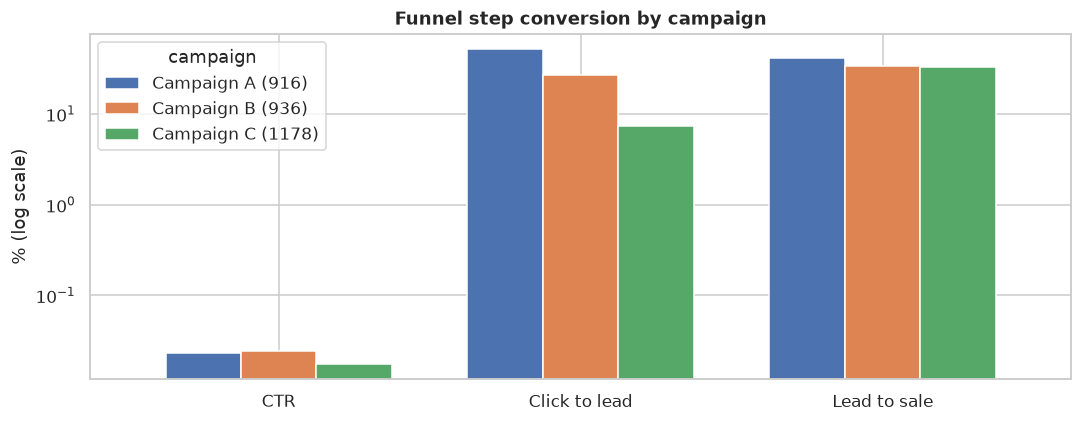

,CTR,Click to lead,Lead to sale
campaign,,,
Campaign A (916),0.02%,51.33%,41.38%
Campaign B (936),0.02%,27.07%,34.08%
Campaign C (1178),0.02%,7.40%,32.67%


In [4]:
funnel = by_campaign[["Impressions", "Clicks", "Leads", "Sales"]]
rates = pd.DataFrame({
    "CTR": funnel["Clicks"] / funnel["Impressions"],
    "Click to lead": funnel["Leads"] / funnel["Clicks"],
    "Lead to sale": funnel["Sales"] / funnel["Leads"],
})
fig, ax = plt.subplots(figsize=(10, 4))
(rates.T * 100).plot.bar(ax=ax, logy=True, width=0.75)
ax.set_ylabel("% (log scale)"); ax.set_title("Funnel step conversion by campaign"); ax.set_xlabel(""); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()
rates.style.format("{:.2%}")

## 3. Wasted spend
**Definition:** spend on ads that produced **zero approved sales**. In Amazon PPC terms, these are the search terms or targets you would negate or pause.

In [5]:
ads["has_sale"] = ads["Sales"] > 0
waste = ads.loc[~ads["has_sale"], "Spend"].sum()
waste_share = waste / ads["Spend"].sum()
w_by_c = ads.groupby("campaign").apply(lambda g: pd.Series({
    "spend": g["Spend"].sum(), "wasted_spend": g.loc[~g["has_sale"], "Spend"].sum(),
    "ads": len(g), "ads_with_zero_sales": (~g["has_sale"]).sum()}))
w_by_c["waste_%"] = w_by_c["wasted_spend"] / w_by_c["spend"]
print(f"Wasted spend: ${waste:,.0f} = {waste_share:.1%} of total spend, across {(~ads['has_sale'] & (ads['Spend'] > 0)).sum()} ads with spend and no approved sale.")
w_by_c.style.format({"spend": "${:,.0f}", "wasted_spend": "${:,.0f}", "waste_%": "{:.1%}"})

Wasted spend: $14,754 = 25.1% of total spend, across 423 ads with spend and no approved sale.


,spend,wasted_spend,ads,ads_with_zero_sales,waste_%
campaign,,,,,
Campaign A (916),$150,$74,54.000000,30.000000,49.6%
Campaign B (936),"$2,893","$1,910",464.000000,292.000000,66.0%
Campaign C (1178),"$55,662","$12,770",625.000000,237.000000,22.9%


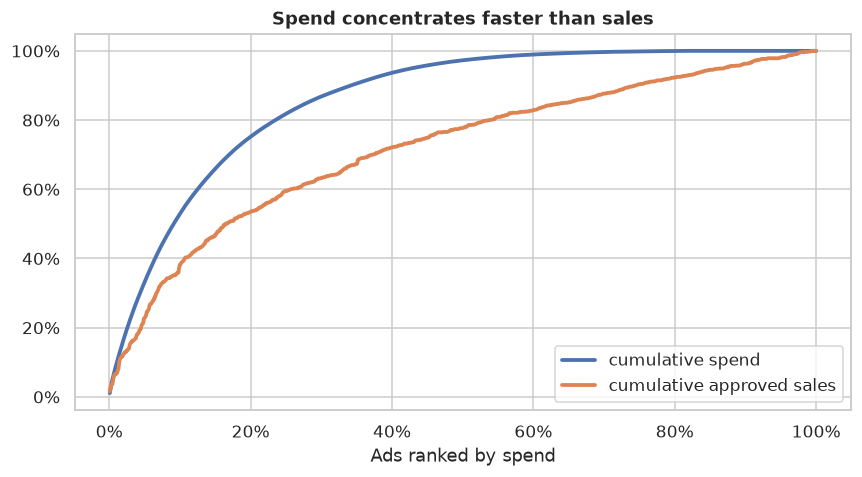

The top 20% of ads by spend use 75% of budget but deliver 53% of approved sales.


In [6]:
# Pareto of spend across ads: does the money concentrate in a few ads?
s = ads.sort_values("Spend", ascending=False)
cum_spend = s["Spend"].cumsum() / s["Spend"].sum()
cum_sales = s["Sales"].cumsum() / s["Sales"].sum()
x = np.arange(1, len(s) + 1) / len(s)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(x, cum_spend, lw=2.5, label="cumulative spend"); ax.plot(x, cum_sales, lw=2.5, label="cumulative approved sales")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Ads ranked by spend"); ax.set_title("Spend concentrates faster than sales"); ax.legend()
plt.tight_layout(); plt.show()
k = int(len(s) * 0.2)
print(f"The top 20% of ads by spend use {cum_spend.iloc[k-1]:.0%} of budget but deliver {cum_sales.iloc[k-1]:.0%} of approved sales.")

## 4. Audience efficiency (the "targeting report")
CPA by demographic cell and by interest. Cells with too little spend are flagged rather than judged, because small samples mislead.

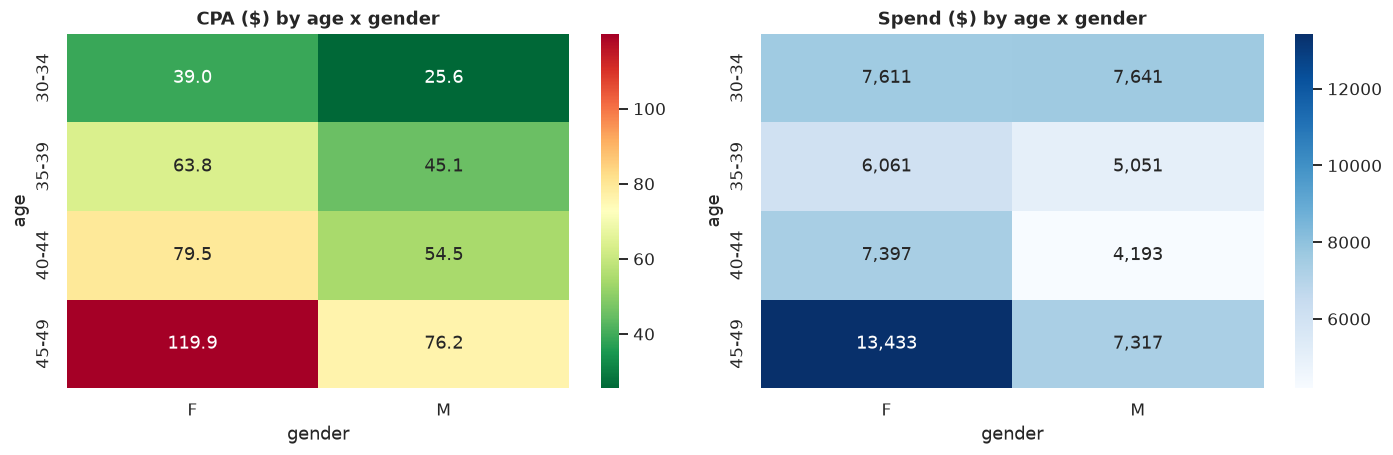

In [7]:
cell = ads.groupby(["age", "gender"]).apply(kpis)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
sns.heatmap(cell["CPA"].unstack(), annot=True, fmt=".1f", cmap="RdYlGn_r", ax=axes[0]); axes[0].set_title("CPA ($) by age x gender")
sns.heatmap(cell["Spend"].unstack(), annot=True, fmt=",.0f", cmap="Blues", ax=axes[1]); axes[1].set_title("Spend ($) by age x gender")
plt.tight_layout(); plt.show()

In [8]:
MIN_SPEND = 2 * TARGET_CPA
interest = ads.groupby("interest").apply(kpis)
interest["status"] = np.select(
    [interest["Spend"] < MIN_SPEND, interest["Sales"] == 0, interest["CPA"] > 1.5 * TARGET_CPA, interest["CPA"] <= TARGET_CPA],
    ["too little data", "PAUSE (no sales)", "REDUCE bids", "SCALE"], default="HOLD / optimise")
summary = interest.groupby("status").agg(interests=("Spend", "size"), spend=("Spend", "sum"), sales=("Sales", "sum"))
summary["CPA"] = summary["spend"] / summary["sales"].replace(0, np.nan)
display(summary.style.format({"spend": "${:,.0f}", "sales": "{:,.0f}", "CPA": "${:.2f}"}))
interest.sort_values("Spend", ascending=False)[["Spend", "Sales", "CPA", "ROAS", "status"]].head(15).style.format({"Spend": "${:,.0f}", "CPA": "${:.2f}", "ROAS": "{:.2f}x"})

,interests,spend,sales,CPA
status,,,,
HOLD / optimise,10,"$13,574",360,$37.70
REDUCE bids,26,"$43,581",655,$66.54
SCALE,4,"$1,550",64,$24.22


,Spend,Sales,CPA,ROAS,status
interest,,,,,
16,"$8,085",141.000000,$57.34,1.74x,REDUCE bids
27,"$5,176",54.000000,$95.85,1.04x,REDUCE bids
10,"$5,086",91.000000,$55.89,1.79x,REDUCE bids
29,"$5,045",132.000000,$38.22,2.62x,HOLD / optimise
28,"$3,206",42.000000,$76.33,1.31x,REDUCE bids
15,"$2,597",63.000000,$41.23,2.43x,HOLD / optimise
63,"$2,484",34.000000,$73.06,1.37x,REDUCE bids
18,"$2,425",33.000000,$73.49,1.36x,REDUCE bids
32,"$1,971",35.000000,$56.30,1.78x,REDUCE bids


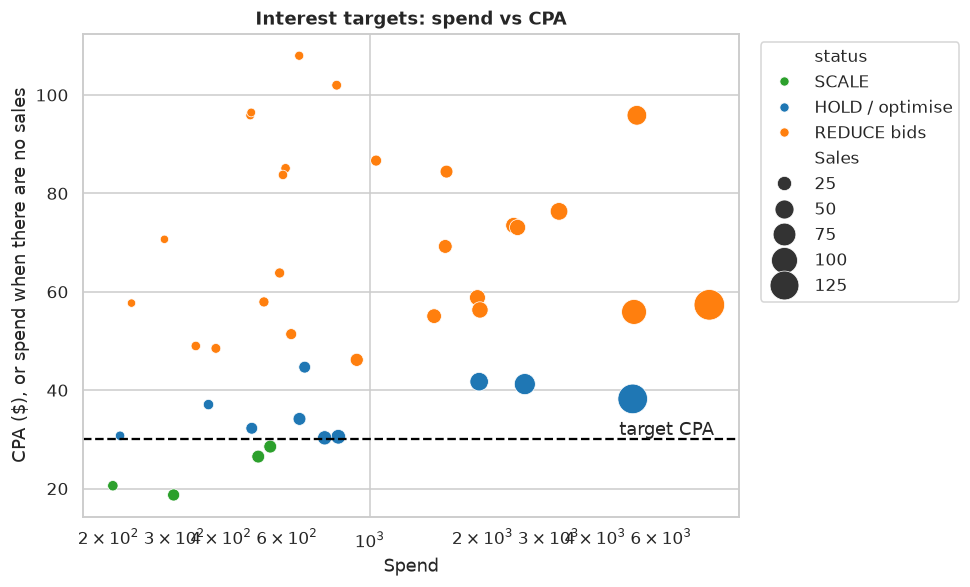

In [9]:
fig, ax = plt.subplots(figsize=(9, 5.5))
pal = {"SCALE": "#2ca02c", "HOLD / optimise": "#1f77b4", "REDUCE bids": "#ff7f0e", "PAUSE (no sales)": "#d62728", "too little data": "#7f7f7f"}
d = interest.assign(CPA_plot=interest["CPA"].fillna(interest["Spend"]))
sns.scatterplot(data=d, x="Spend", y="CPA_plot", hue="status", size="Sales", sizes=(30, 400), palette=pal, ax=ax)
ax.axhline(TARGET_CPA, ls="--", c="black"); ax.text(ax.get_xlim()[1] * 0.98, TARGET_CPA, " target CPA", va="bottom", ha="right")
ax.set_xscale("log"); ax.set_ylabel("CPA ($), or spend when there are no sales"); ax.set_title("Interest targets: spend vs CPA")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left"); plt.tight_layout(); plt.show()

## 5. Optimisation rules and what-if simulation
These are the same rules I'd apply to an Amazon search-term report, run here at ad level:

| Rule | Condition | Action |
|---|---|---|
| **Negate / pause** | spend ≥ 2 × target CPA and 0 sales | pause the ad (or negate the term) |
| **Reduce** | CPA > 1.5 × target CPA | cut bid or budget by 30% |
| **Scale** | CPA ≤ target CPA and at least 2 sales | move the freed budget here |

Simulation assumption: reallocated budget converts at **50%** of the receiving ads' current efficiency, which allows for diminishing returns. A "reduced" ad keeps 85% of its sales on 70% of its spend.

,ads paused,ads reduced,ads scaled,budget moved ($),baseline sales,projected sales,baseline CPA ($),projected CPA ($),sales uplift
same budget,71.000000,172.000000,69.000000,"$18,371","1,079","1,594",$54.41,$36.83,+47.7%


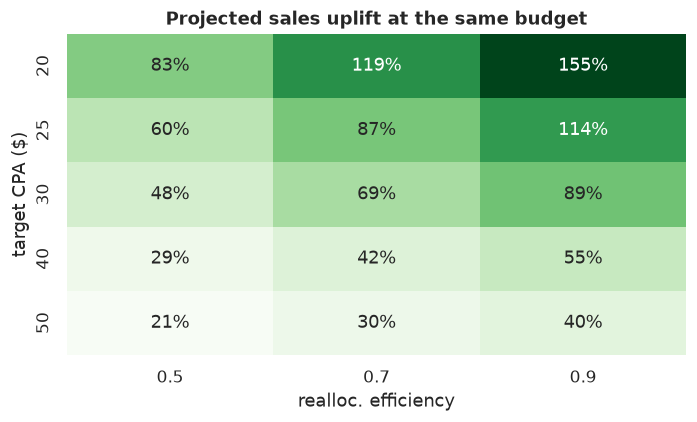

In [10]:
def simulate(df, target_cpa=TARGET_CPA, realloc_eff=0.5):
    d = df.copy()
    d["CPA"] = d["Spend"] / d["Sales"].replace(0, np.nan)
    pause = (d["Spend"] >= 2 * target_cpa) & (d["Sales"] == 0)
    reduce_ = (~pause) & (d["CPA"] > 1.5 * target_cpa)
    scale = (~pause) & (~reduce_) & (d["CPA"] <= target_cpa) & (d["Sales"] >= 2)
    freed = d.loc[pause, "Spend"].sum() + 0.3 * d.loc[reduce_, "Spend"].sum()
    base_sales, base_spend = d["Sales"].sum(), d["Spend"].sum()
    lost_sales = 0.15 * d.loc[reduce_, "Sales"].sum()
    scale_cpa = d.loc[scale, "Spend"].sum() / max(d.loc[scale, "Sales"].sum(), 1)
    gained = freed / scale_cpa * realloc_eff if scale.any() else 0
    new_sales = base_sales - lost_sales + gained
    return pd.Series({"ads paused": int(pause.sum()), "ads reduced": int(reduce_.sum()), "ads scaled": int(scale.sum()),
                      "budget moved ($)": freed, "baseline sales": base_sales, "projected sales": new_sales,
                      "baseline CPA ($)": base_spend / base_sales, "projected CPA ($)": base_spend / new_sales,
                      "sales uplift": new_sales / base_sales - 1})

res = simulate(ads)
display(res.to_frame("same budget").T.style.format({"budget moved ($)": "${:,.0f}", "baseline sales": "{:,.0f}", "projected sales": "{:,.0f}",
                                                     "baseline CPA ($)": "${:.2f}", "projected CPA ($)": "${:.2f}", "sales uplift": "{:+.1%}"}))

# Sensitivity: how robust is the uplift to the target CPA and reallocation efficiency?
sens = pd.DataFrame({eff: {t: simulate(ads, t, eff)["sales uplift"] for t in [20, 25, 30, 40, 50]} for eff in [0.5, 0.7, 0.9]})
sens.index.name = "target CPA ($)"; sens.columns.name = "realloc. efficiency"
fig, ax = plt.subplots(figsize=(6.5, 4))
sns.heatmap(sens, annot=True, fmt=".0%", cmap="Greens", ax=ax, cbar=False); ax.set_title("Projected sales uplift at the same budget")
plt.tight_layout(); plt.show()

## 6. Conclusions

In [11]:
best_cell = cell[cell["Spend"] > MIN_SPEND]["CPA"].idxmin(); worst_cell = cell[cell["Spend"] > MIN_SPEND]["CPA"].idxmax()
print(f"1. {waste_share:.0%} of spend (${waste:,.0f}) went to ads with zero approved sales. That is the first budget to recover.")
print(f"2. Account CPA is ${total['CPA'].iloc[0]:.2f} against a ${TARGET_CPA:.0f} target, so ROAS at the assumed ${VALUE_PER_CONVERSION:.0f}/sale is {total['ROAS'].iloc[0]:.2f}x.")
print(f"3. The best audience cell is {best_cell[0]} {best_cell[1]} (CPA ${cell.loc[best_cell,'CPA']:.2f}). The worst is {worst_cell[0]} {worst_cell[1]} (CPA ${cell.loc[worst_cell,'CPA']:.2f}).")
print(f"4. Three simple rules (pause, reduce, scale) project {res['sales uplift']:+.0%} more approved sales at the same budget, with CPA moving from ${res['baseline CPA ($)']:.2f} to ${res['projected CPA ($)']:.2f}.")

1. 25% of spend ($14,754) went to ads with zero approved sales. That is the first budget to recover.
2. Account CPA is $54.41 against a $30 target, so ROAS at the assumed $100/sale is 1.84x.
3. The best audience cell is 30-34 M (CPA $25.55). The worst is 45-49 F (CPA $119.94).
4. Three simple rules (pause, reduce, scale) project +48% more approved sales at the same budget, with CPA moving from $54.41 to $36.83.


**How to use this on a real account (Amazon, Google or Meta):** export the search-term or targeting report, map the columns to `Impressions, Clicks, Spend, Leads/Orders, Sales`, set `TARGET_CPA` from product margin (break-even ACoS = margin %), and re-run. Run it weekly and roll changes out gradually. Test rule changes on a share of campaigns first.

**Limitations:** the revenue per sale is assumed, the data is a single snapshot without dates, and the reallocation model is a simple linear one. Treat the uplift as a direction to test, not a guarantee.

*If this was useful, an upvote helps. Questions and feedback are welcome in the comments.*

---
**Shahzad Raza** · E-commerce & marketing data analyst · [GitHub](https://github.com/Shahzrazaa) · [LinkedIn](https://www.linkedin.com/in/shahzadrazaa/)

📋 Free Amazon listing health checklist: https://adsmithai.gumroad.com/l/rxzumn

More notebooks: https://www.kaggle.com/shahzadrazaa/code